# Evidence relationship labels

**Recipe 34** · Level 3 (Intermediate) · Decision type: `Choice`

Label candidate entity pairs with an allowed relationship type or `no_supported_relation` using provided evidence passages.

Sources:

- S02: [TypeSafe AI: Primitives (Questions)](https://docs.typesafe.ai/primitives)
- S03: [TypeSafe AI: Confidence](https://docs.typesafe.ai/confidence)
- S06: [TypeSafe AI: Cookbooks](https://docs.typesafe.ai/cookbooks)

## What you will build

A small knowledge-graph labeller for fabricated entity pairs. Each candidate pair comes with one or more evidence passages someone has already retrieved for it; Jev reads one passage at a time and answers one `Choice`, picking exactly one of four fixed relationship types or the fallback outcome, `no_supported_relation`, for that single passage. Python never asks Jev about a whole pair at once and never asks whether a relationship is *true* -- only whether *this passage* states it. Two stages of Python then turn those passage-level answers into one task-level label per entity pair: a confidence gate on each passage, and a deterministic rule that composes every passage decision for one pair, sending the pair to an explicit review outcome when the evidence disagrees or when any passage was not confident enough to trust. By the end you will have looked at the hard case this use case names by name -- a pair that is related in exactly the way this recipe's own fixtures establish elsewhere, but whose passage here does not say so -- and run an evaluation that reports per-relationship precision, recall and F1 at two different granularities: per evidence passage, and per composed, task-level pair.


## Setup and run mode

The notebook runs from its own folder with the standard library and `jev_cookbook` only. `get_backend(fixtures=...)` replays the 30 stored evidence-passage answers in `fixtures/responses.json` offline; setting `JEV_COOKBOOK_LIVE=1` (see the README) swaps in live calls to the same question definition and changes nothing else. `run_header` states which mode ran. Two labels may follow a number below. `(a pipeline check, not a Jev result)` marks a synthetic or scripted run; a recorded or live run does not print it, and its header says which mode ran. `(a selection step, not a reported result)` marks a number used to choose a setting on `validation`. A line with neither label, such as an individual answer or a per-example line, still comes from the mode the header names.


In [1]:
from jev_cookbook import get_backend, load_helpers
from jev_cookbook.evaluation import (
    accuracy,
    confusion_matrix,
    evaluate_outcomes,
    per_class_metrics,
    select_confidence_threshold,
    selective_curve,
)
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path, select_split
from jev_cookbook.simulation import ReviewQueue
from jev_cookbook.style import (
    apply_style,
    plot_answer_probabilities,
    plot_confusion_matrix,
    plot_risk_coverage,
    run_header,
    show_answer,
)

apply_style()
helpers = load_helpers()  # this recipe's helpers.py, loaded by path
examples = load_inputs()
labels = load_labels()
backend = get_backend(fixtures=responses_path())
by_id = {e.id: e for e in examples}
# N for the header is the number of entity-pair tasks the metrics are about: validation and
# test. This recipe has no train split; the demo task is shown but never scored.
scored = [e for e in examples if e.split not in ("train", "demo")]

offline = backend.mode in ("synthetic", "scripted")
check = " (a pipeline check, not a Jev result)" if offline else ""
# CONTRIBUTING.md section 2: a number from the validation split is a selection step, not a
# result. This label does not depend on the run mode, unlike `check` above.
selection = " (a selection step, not a reported result)"

# Every evidence passage needs at most one request, whichever task it belongs to. This cache
# makes sure a passage shown individually and later scored as part of its task's split is
# decided once, so the whole notebook makes exactly one request per distinct passage in live
# mode (30 across every fixture, scored and demo alike).
answered = {}


def decide_passages(example):
    """Every evidence passage's answer for one task, decided once each and cached by passage
    id, in the fixed order helpers.passage_states yields them."""
    results = {}
    for passage_id, state in helpers.passage_states(example.fields):
        if passage_id not in answered:
            answered[passage_id] = backend.decide(state, questions)["relation"]
        results[passage_id] = answered[passage_id]
    return results


run_header(34, "Evidence relationship labels", backend=backend, n_examples=len(scored))

Recipe 34: Evidence relationship labels
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 24 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

Each task in `fixtures/inputs.jsonl` carries `fields`: a `pair_id`, the two entity names `entity_a` and `entity_b`, and a list of `passages`, each with its own `passage_id` and `text`. Jev is never asked about a whole task at once: `build_state` turns a *single* passage into the state for a *single* request -- the two entity names and that one passage's text, nothing else -- so a task with several passages makes one request per passage, each judged on its own. `pair_id` and every `passage_id` stay in Python and are reattached to the outcome afterwards; neither passes through the model, so every label still traces back to the passage it came from.


In [2]:
import json

d01 = by_id["d01"]
print("Python has:")
print(json.dumps(d01.fields, indent=2))
d01_passage_id, d01_state = next(helpers.passage_states(d01.fields))
print(f"Jev sees, for passage {d01_passage_id!r}:")
print(json.dumps(d01_state, indent=2))

Python has:
{
  "pair_id": "d01",
  "entity_a": "Omar Delacroix",
  "entity_b": "Thornwell Systems",
  "passages": [
    {
      "passage_id": "d01-ev1",
      "text": "Omar Delacroix joined Thornwell Systems as a product manager earlier this year."
    }
  ]
}
Jev sees, for passage 'd01-ev1':
{
  "entity_a": "Omar Delacroix",
  "entity_b": "Thornwell Systems",
  "passage": "Omar Delacroix joined Thornwell Systems as a product manager earlier this year."
}


## The questions

There is one question, asked once per evidence passage: which relationship, if any, does *this passage* state holds between `entity_a` and `entity_b`? The candidate set -- four fixed relationship types plus `no_supported_relation` -- is built by Python and printed below, so the reader sees exactly what Jev is allowed to choose among. `no_supported_relation` is not a last resort for "none of the others fit cleanly"; it is the use case's own fallback outcome, and it is the right answer whenever a passage does not settle the relationship, whatever else is true about the two entities. This follows the general evidence-grounding shape TypeSafe's cookbooks describe for citation checking (S06): judge only what the passage in front of you states, never what you might know or infer about the entities from elsewhere.

A `Choice` answer's [confidence](../../docs/glossary.md#confidence) is the top probability rescaled by the number of options, `(p_max - 1/n) / (1 - 1/n)`: 0 when the top option has no more than an even share of the five, 1 when one option holds all the probability.


In [3]:
questions = helpers.build_questions()
relation = questions["relation"]
print(relation.instructions)
for name, description in relation.criteria.items():
    print(f"  {name:22s} {description}")

Which relationship, if any, does this passage state holds between entity_a and entity_b? Judge only what the passage itself says, not what you may know or guess about the two entities from elsewhere.
  works_for              The passage states that entity_a is an employee of, or works for, entity_b -- for example naming a role, a job, or a period of employment at entity_b.
  founder_of             The passage states that entity_a founded, started, or co-founded entity_b -- not merely that entity_a currently works there or sits on its board.
  acquired_by            The passage states that entity_b acquired, bought, or took over entity_a, so that entity_a was acquired by entity_b.
  supplier_of            The passage states that entity_a supplies goods, materials, or services that entity_b uses -- entity_a is a supplier of entity_b.
  no_supported_relation  The passage does not state any of the relationships above holding between entity_a and entity_b. This covers a passage that is sile

## One answer up close

Before any aggregate number, look at four individual passage answers: a simple accepted relationship and a simple accepted fallback, then the hard case this use case names by name, then two passages about the same pair that disagree. Each holds the chosen option, a probability for every option, the confidence explained above, and a `provenance` line -- here always `synthetic`, since nothing in this recipe's fixtures came from a real call.


Omar Delacroix / Thornwell Systems
Omar Delacroix joined Thornwell Systems as a product manager earlier this year.
Choice: works_for (confidence 0.85)
  works_for              0.88  ##################
  founder_of             0.03  #
  acquired_by            0.03  #
  supplier_of            0.03  #
  no_supported_relation  0.03  #
Provenance: synthetic


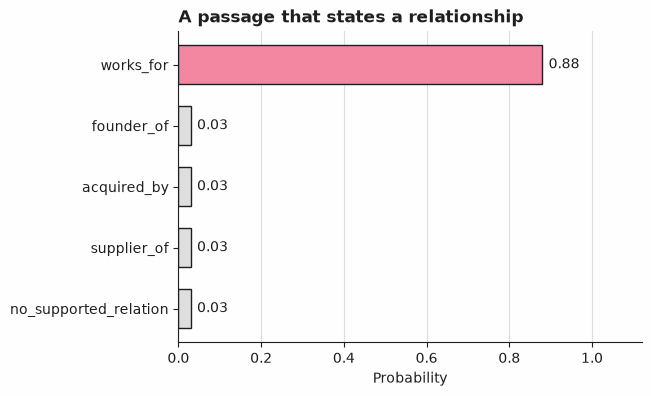

In [4]:
d01_answer = decide_passages(d01)[d01_passage_id]
print(f"{d01.fields['entity_a']} / {d01.fields['entity_b']}")
print(d01.fields["passages"][0]["text"])
show_answer(d01_answer)
plot_answer_probabilities(d01_answer, title="A passage that states a relationship")

In [5]:
d02 = by_id["d02"]
d02_passage = d02.fields["passages"][0]
d02_answer = decide_passages(d02)[d02_passage["passage_id"]]
print(f"{d02.fields['entity_a']} / {d02.fields['entity_b']}")
print(d02_passage["text"])
show_answer(d02_answer)

Omar Delacroix / Vexam Analytics
Omar Delacroix attended a product conference where Vexam Analytics also had a booth.
Choice: no_supported_relation (confidence 0.75)
  no_supported_relation  0.80  ################
  works_for              0.05  #
  founder_of             0.05  #
  acquired_by            0.05  #
  supplier_of            0.05  #
Provenance: synthetic


`d01`'s passage plainly states an employment relationship, and the stored answer puts `works_for` on top with little left over for the other four options. `d02`'s passage only places the same person at a conference where a different company happened to have a booth; it never relates the two beyond that, and the stored answer correctly, confidently, calls it `no_supported_relation` -- the fallback is not a weaker answer than the other four, it is the right one whenever the evidence does not go further than this.


Priya Oduya / Thornwell Systems
Priya Oduya has worked as a senior engineer at Thornwell Systems since March 2019, leading its platform reliability team.
Choice: works_for (confidence 0.87)
  works_for              0.90  ##################
  founder_of             0.02  
  acquired_by            0.02  
  supplier_of            0.02  
  no_supported_relation  0.02  
Provenance: synthetic


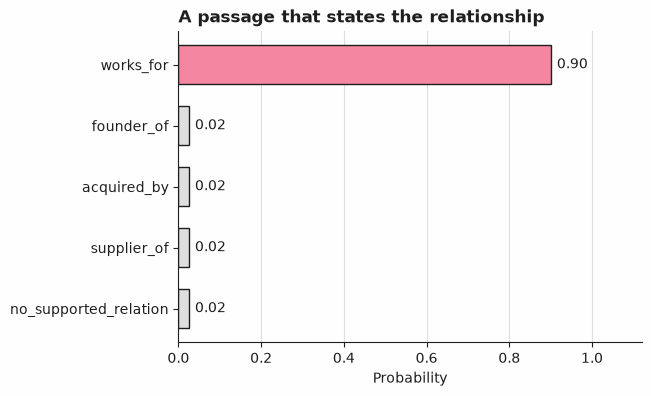

In [6]:
v01 = by_id["v01"]
v01_passage = v01.fields["passages"][0]
v01_answer = decide_passages(v01)[v01_passage["passage_id"]]
print(f"{v01.fields['entity_a']} / {v01.fields['entity_b']}")
print(v01_passage["text"])
show_answer(v01_answer)
plot_answer_probabilities(v01_answer, title="A passage that states the relationship")

Priya Oduya / Thornwell Systems (the same two entities as above)
Priya Oduya was one of several panelists at the Northfield Data Summit, an event Thornwell Systems helped sponsor that year.
Choice: no_supported_relation (confidence 0.73)
  no_supported_relation  0.78  ################
  works_for              0.05  #
  founder_of             0.05  #
  acquired_by            0.05  #
  supplier_of            0.05  #
Provenance: synthetic


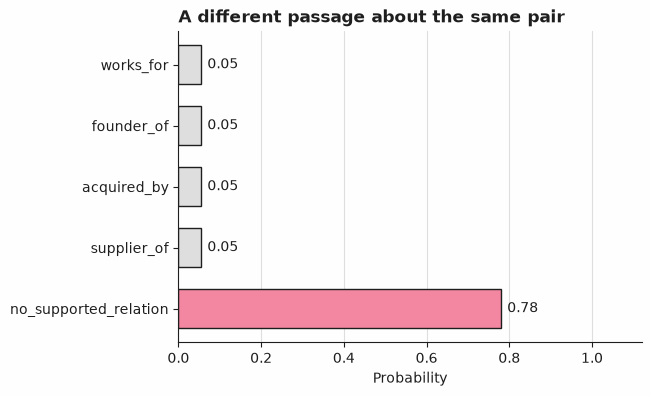

In [7]:
v05 = by_id["v05-hard"]
v05_passage = v05.fields["passages"][0]
v05_answer = decide_passages(v05)[v05_passage["passage_id"]]
print(f"{v05.fields['entity_a']} / {v05.fields['entity_b']} (the same two entities as above)")
print(v05_passage["text"])
show_answer(v05_answer)
plot_answer_probabilities(v05_answer, title="A different passage about the same pair")

`v01` and `v05-hard` name the same two entities, Priya Oduya and Thornwell Systems, and the relationship between them really is `works_for` -- `v01`'s passage states it outright, and `v01` is a normal, scored task in this recipe's own `validation` split. `v05-hard` is a *different* task over the *same* pair: its passage only places Priya Oduya on a conference panel at an event Thornwell Systems helped sponsor, and never says she works there. The decision under test is never "is this relationship true"; it is "does *this* passage support it", and the honest answer for `v05-hard`'s own passage is `no_supported_relation`, even though the pair is related in exactly the way `v01` establishes elsewhere in this recipe's own fixtures. A rule that answered from what it already "knew" about the pair, rather than from the passage in front of it, would get `v05-hard` wrong by construction; the stored answer above does not, and it is confident about it, not merely unsure.


In [8]:
v11 = by_id["v11-disagree"]
v11_answers = decide_passages(v11)
for passage in v11.fields["passages"]:
    print(f"{v11.fields['entity_a']} / {v11.fields['entity_b']}  [{passage['passage_id']}]")
    print(passage["text"])
    show_answer(v11_answers[passage["passage_id"]])
    print()

Ines Alderman / Dunmore Chemicals  [v11-ev1]
Ines Alderman founded Dunmore Chemicals in 2003 and still sits on its board.
Choice: founder_of (confidence 0.84)
  founder_of             0.87  #################
  works_for              0.03  #
  acquired_by            0.03  #
  supplier_of            0.03  #
  no_supported_relation  0.03  #
Provenance: synthetic

Ines Alderman / Dunmore Chemicals  [v11-ev2]
Ines Alderman also spent a year on secondment to Dunmore Chemicals' regional office before returning to lead the company she started.
Choice: works_for (confidence 0.68)
  works_for              0.74  ###############
  founder_of             0.07  #
  acquired_by            0.07  #
  supplier_of            0.07  #
  no_supported_relation  0.07  #
Provenance: synthetic



`v11-disagree` has two evidence passages about the same pair. The first plainly supports `founder_of`, and the stored answer agrees, confidently. The second passage mentions a secondment at the same company but never says Ines Alderman founded it or works for it in the sense any of the four relationships names; the honest passage-level answer is `no_supported_relation`, but the stored answer here is deliberately imperfect: it confidently misreads the secondment as `works_for`. Composing the two passage-level answers into one task-level label for the pair is Python's job, next.


## Python's part

Jev supplies one judgment per passage; what happens with several of them is code, in two stages, both in `helpers.py`:

1. `classify_passage` gates one passage's answer on confidence alone. Every option -- `no_supported_relation` included -- is a label Python is willing to report for a single passage, so confidence is the only thing this stage checks: at or above a [confidence gate](../../docs/glossary.md#confidence-gate) the label is accepted, below it the passage goes to an explicit [review](../../docs/glossary.md#review) outcome, whatever the label is.
2. `compose_relation` composes every passage decision for one entity pair into a single task-level label. Any passage below the confidence gate sends the whole pair to review -- a reviewer, not a forced guess, decides a pair Python is not confident enough about on even one piece of evidence. Otherwise, the distinct real relationships the accepted passages name are collected: zero means the pair's label is `no_supported_relation`; exactly one (named by one or every accepted passage) is reported as the pair's label; more than one means the evidence disagrees, so the pair goes to review rather than Python silently preferring one passage over another.

The confidence gate is chosen once, here, on `validation`, from every scored passage across the whole split (not per task), and then frozen for the rest of this notebook: `select_confidence_threshold(..., min_coverage=...)` picks, among the gates that would still answer at least a `min_coverage` share of validation passages, the one with the highest accuracy among what it answers (ties go to the lower gate, i.e. more coverage).


In [9]:
val_examples = select_split(examples, "validation")
val_passage_rows = []  # (example_id, passage_id, answer, gold)
for example in val_examples:
    answers = decide_passages(example)
    for passage_id, answer in answers.items():
        gold = helpers.passage_gold(labels[example.id], passage_id)
        val_passage_rows.append((example.id, passage_id, answer, gold))

val_correct = [a.choice == g for _eid, _pid, a, g in val_passage_rows]
val_confidence = [a.confidence for _eid, _pid, a, g in val_passage_rows]
MIN_COVERAGE = helpers.MIN_COVERAGE
threshold = select_confidence_threshold(val_correct, val_confidence, min_coverage=MIN_COVERAGE)
print(
    f"chosen confidence gate, frozen from here on: {threshold:.4f} "
    f"(highest accuracy with coverage >= {MIN_COVERAGE}){selection}{check}"
)

for task_id in ("v01", "v05-hard", "v09-low", "v11-disagree"):
    task = by_id[task_id]
    decisions = tuple(
        helpers.classify_passage(pid, a, threshold) for pid, a in decide_passages(task).items()
    )
    outcome = helpers.compose_relation(task_id, decisions)
    shown = outcome.label if outcome.outcome == helpers.ACCEPTED else "withheld"
    print(f"{task_id}: {shown} -> {outcome.outcome} ({outcome.reason}){check}")

chosen confidence gate, frozen from here on: 0.6750 (highest accuracy with coverage >= 0.85) (a selection step, not a reported result) (a pipeline check, not a Jev result)
v01: works_for -> accepted (composed from its evidence) (a pipeline check, not a Jev result)
v05-hard: no_supported_relation -> accepted (composed from its evidence) (a pipeline check, not a Jev result)
v09-low: withheld -> review (confidence below the threshold) (a pipeline check, not a Jev result)
v11-disagree: withheld -> review (evidence passages disagree on the relation) (a pipeline check, not a Jev result)


Every value strictly between the chosen gate and the next distinct validation confidence above it would freeze the same answered set, so the sweep below shows every distinct confidence value the selector considered, with accuracy, [risk](../../docs/glossary.md#risk) and [coverage](../../docs/glossary.md#coverage) at each ([selective prediction](../../docs/glossary.md#selective-prediction); `selective_curve`). Looking at the curve, not just the one chosen number, is what shows that confidence genuinely separates right from wrong on this split, rather than merely asserting it.


gate 0.8750  coverage 0.0714  accuracy 1.0000  risk 0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
gate 0.8625  coverage 0.1429  accuracy 1.0000  risk 0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
gate 0.8500  coverage 0.2143  accuracy 1.0000  risk 0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
gate 0.8375  coverage 0.2857  accuracy 1.0000  risk 0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
gate 0.8125  coverage 0.3571  accuracy 1.0000  risk 0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
gate 0.8000  coverage 0.4286  accuracy 1.0000  risk 0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
gate 0.7875  coverage 0.5000  accuracy 1.0000  risk 0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
gate 0.7625  coverage 0.5714  accu

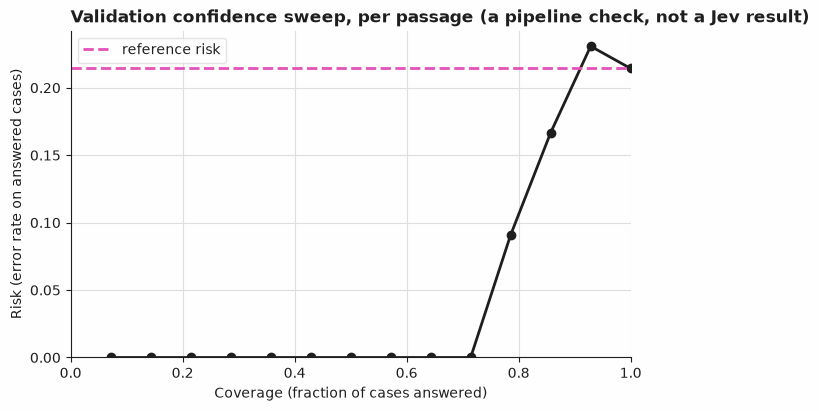

In [10]:
val_curve = selective_curve(val_correct, val_confidence)
for t, cov, acc, risk in zip(
    val_curve.thresholds, val_curve.coverage, val_curve.accuracy, val_curve.risk, strict=True
):
    print(
        f"gate {t:.4f}  coverage {cov:.4f}  accuracy {acc:.4f}  risk {risk:.4f}{selection}{check}"
    )

val_pred = [a.choice for _eid, _pid, a, g in val_passage_rows]
val_gold = [g for _eid, _pid, a, g in val_passage_rows]
val_ungated_risk = 1 - accuracy(val_gold, val_pred)
plot_risk_coverage(
    val_curve,
    reference_risk=val_ungated_risk,
    title=f"Validation confidence sweep, per passage{check}",
)

## Evaluation

This recipe reports two different things, at two different granularities, and keeping them apart matters:

- **Per question**: how often the *passage-level* answer -- `classify_passage`'s label, before any composition -- matches that passage's own [gold label](../../docs/glossary.md#gold-label), over every scored evidence passage.
- **Task level**: how often the *composed* label `compose_relation` reports for a whole entity pair matches that pair's own gold label, over every scored task that composition did not send to review.

These are two different set sizes, and the rest of this notebook names which one each number is about: this recipe's scored *passages* (one per question actually asked) number 14 on `validation` and 14 on `test`; its scored *tasks* (one per entity pair, the groups the task-level numbers are computed over) number 12 on each split, because four tasks per split bundle two evidence passages. `helpers.classify_passage` and `helpers.compose_relation` are applied to every example in `validation` and in `test`, and every count below comes from what they actually return, not from a separate reimplementation of either rule. In an offline run every `test` number is a check that the pipeline works, and it says so; every `validation` number, in every run mode, is a selection step rather than a reported result.


In [11]:
queue = ReviewQueue()

val_task_decisions = {}
for example in val_examples:
    answers = decide_passages(example)
    val_task_decisions[example.id] = tuple(
        helpers.classify_passage(pid, a, threshold) for pid, a in answers.items()
    )
val_task_outcomes = {
    eid: helpers.compose_relation(eid, decisions) for eid, decisions in val_task_decisions.items()
}
helpers.submit_reviews(queue, val_examples, val_task_outcomes)

print(f"validation, {len(val_passage_rows)} passages (per question){selection}{check}")
print(
    f"  accuracy of the passage-level choice: {accuracy(val_gold, val_pred):.4f}{selection}{check}"
)

val_accepted_tasks = [o for o in val_task_outcomes.values() if o.outcome == helpers.ACCEPTED]
val_task_correct = sum(o.label == helpers.task_gold(labels[o.pair_id]) for o in val_accepted_tasks)
print(f"validation, {len(val_examples)} tasks{selection}{check}")
print(
    f"  accepted by composition: {len(val_accepted_tasks)} of {len(val_examples)}{selection}{check}"
)
print(
    f"  right among those accepted: {val_task_correct} of {len(val_accepted_tasks)}{selection}{check}"
)

validation, 14 passages (per question) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  accuracy of the passage-level choice: 0.7857 (a selection step, not a reported result) (a pipeline check, not a Jev result)
validation, 12 tasks (a selection step, not a reported result) (a pipeline check, not a Jev result)
  accepted by composition: 9 of 12 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  right among those accepted: 8 of 9 (a selection step, not a reported result) (a pipeline check, not a Jev result)


In [12]:
test_examples = select_split(examples, "test")
test_passage_rows = []
test_task_decisions = {}
for example in test_examples:
    answers = decide_passages(example)
    for passage_id, answer in answers.items():
        gold = helpers.passage_gold(labels[example.id], passage_id)
        test_passage_rows.append((example.id, passage_id, answer, gold))
    test_task_decisions[example.id] = tuple(
        helpers.classify_passage(pid, a, threshold) for pid, a in answers.items()
    )
test_task_outcomes = {
    eid: helpers.compose_relation(eid, decisions) for eid, decisions in test_task_decisions.items()
}
helpers.submit_reviews(queue, test_examples, test_task_outcomes)

test_pred = [a.choice for _eid, _pid, a, g in test_passage_rows]
test_gold = [g for _eid, _pid, a, g in test_passage_rows]
print(f"test, {len(test_passage_rows)} passages (per question), gate {threshold:.4f} frozen{check}")
print(f"  accuracy of the passage-level choice: {accuracy(test_gold, test_pred):.4f}{check}")

test_accepted_tasks = [o for o in test_task_outcomes.values() if o.outcome == helpers.ACCEPTED]
test_task_correct = sum(
    o.label == helpers.task_gold(labels[o.pair_id]) for o in test_accepted_tasks
)
print(f"test, {len(test_examples)} tasks{check}")
print(f"  accepted by composition: {len(test_accepted_tasks)} of {len(test_examples)}{check}")
print(f"  right among those accepted: {test_task_correct} of {len(test_accepted_tasks)}{check}")

print()
print(f"review queue, both splits, {len(queue)} pairs{check}:")
for item in queue.to_dicts():
    print(f"  #{item['id']} {item['item']['pair_id']}: {item['reason']}{check}")

test, 14 passages (per question), gate 0.6750 frozen (a pipeline check, not a Jev result)
  accuracy of the passage-level choice: 0.7857 (a pipeline check, not a Jev result)
test, 12 tasks (a pipeline check, not a Jev result)
  accepted by composition: 10 of 12 (a pipeline check, not a Jev result)
  right among those accepted: 8 of 10 (a pipeline check, not a Jev result)

review queue, both splits, 5 pairs (a pipeline check, not a Jev result):
  #0 v07-wrong: confidence below the threshold (a pipeline check, not a Jev result)
  #1 v09-low: confidence below the threshold (a pipeline check, not a Jev result)
  #2 v11-disagree: evidence passages disagree on the relation (a pipeline check, not a Jev result)
  #3 t09-low: confidence below the threshold (a pipeline check, not a Jev result)
  #4 t11-disagree: evidence passages disagree on the relation (a pipeline check, not a Jev result)


Test confusion matrix, per passage, gold rows by predicted columns (a pipeline check, not a Jev result):
  predicted ->                            works_for             founder_of            acquired_by            supplier_of  no_supported_relation (a pipeline check, not a Jev result)
  gold works_for                                  2                      0                      0                      1                      0 (a pipeline check, not a Jev result)
  gold founder_of                                 0                      4                      0                      0                      0 (a pipeline check, not a Jev result)
  gold acquired_by                                0                      0                      2                      0                      0 (a pipeline check, not a Jev result)
  gold supplier_of                                0                      0                      0                      2                      1 (a pipeline check, not a Je

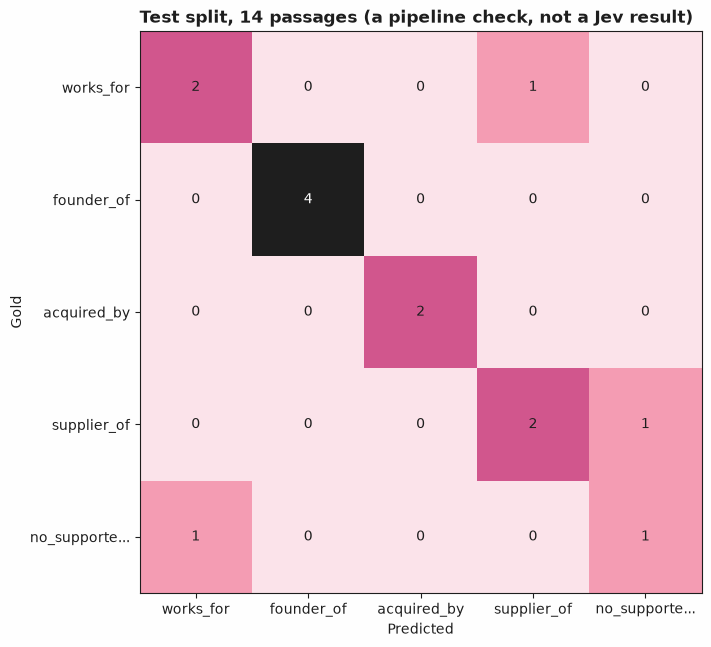

In [13]:
matrix = confusion_matrix(test_gold, test_pred, labels=list(helpers.OPTIONS))
width = max(len(label) for label in matrix.labels)
# The header's leader ("predicted ->") and each row's leader ("gold <label>") are different
# fixed phrases; padding both to the same leader_width, derived from this same width, is what
# keeps the header's columns and every row's columns lined up.
leader_width = max(width + len("gold "), len("predicted ->"))
header = "  ".join(f"{label:>{width}s}" for label in matrix.labels)
print(f"Test confusion matrix, per passage, gold rows by predicted columns{check}:")
print(f"  {'predicted ->':<{leader_width}s}  {header}{check}")
for gold_label, row in zip(matrix.labels, matrix.matrix.tolist(), strict=True):
    counts = "  ".join(f"{count:{width}d}" for count in row)
    leader = f"gold {gold_label:<{width}s}"
    print(f"  {leader:<{leader_width}s}  {counts}{check}")
plot_confusion_matrix(matrix, title=f"Test split, {len(test_passage_rows)} passages{check}")

In [14]:
print(f"test tasks the composition gets wrong, and why{check}:")
for eid, outcome in test_task_outcomes.items():
    gold = helpers.task_gold(labels[eid])
    if outcome.outcome == helpers.ACCEPTED and outcome.label != gold:
        confidences = ", ".join(f"{d.passage_id}={d.confidence:.4f}" for d in outcome.decisions)
        print(f"  {eid}: gold {gold!r}, composed {outcome.label!r} ({confidences}){check}")

test tasks the composition gets wrong, and why (a pipeline check, not a Jev result):
  t07-wrong: gold 'works_for', composed 'supplier_of' (t07-ev1=0.6875) (a pipeline check, not a Jev result)
  t12-fallback-wrong: gold 'supplier_of', composed 'no_supported_relation' (t12-ev1=0.7000) (a pipeline check, not a Jev result)


Both test-split misses are confident mistakes on single-passage tasks, not disagreements: `t07-wrong`'s passage says plainly that Renata Voss has worked as an analyst at Ashgrove Capital, which is `works_for`, but the stored answer confidently names `supplier_of` instead; `t12-fallback-wrong`'s passage says Petrel Logistics has handled freight forwarding for Dunmore Chemicals, which is `supplier_of`, but the stored answer confidently retreats to the fallback, `no_supported_relation`, even though the passage does name a relationship. Both answers clear the frozen gate, so composition reports them as the pair's final label; this is exactly what a confidence gate chosen on `validation` does not promise to catch on data it has not seen, and it is also why the fallback option is not exempt from the gate here -- a confidently wrong `no_supported_relation` is still a miss composition can make, the same as a confidently wrong real relationship.


For each relationship type (`no_supported_relation` included), [precision](../../docs/glossary.md#precision) is the fraction of the passages the stored answers named that label for, before any gate, that really carry it as their gold label; [recall](../../docs/glossary.md#recall) is the fraction of that label's real passages the stored answers actually named; [F1](../../docs/glossary.md#f1) is their harmonic mean, a single number that falls when either does; [support](../../docs/glossary.md#support) is how many `test` passages actually carry that gold label. This is the **per question** view: every scored passage counts once, whether or not the task it belongs to was later sent to review.


In [15]:
per_class = per_class_metrics(test_gold, test_pred, labels=list(helpers.OPTIONS))
print(f"per-relation F1, per question (passage level), test{check}:")
for label in helpers.OPTIONS:
    m = per_class[label]
    print(
        f"  {label:22s} precision {m.precision:.4f}  recall {m.recall:.4f}  "
        f"f1 {m.f1:.4f}  support {m.support}{check}"
    )

per-relation F1, per question (passage level), test (a pipeline check, not a Jev result):
  works_for              precision 0.6667  recall 0.6667  f1 0.6667  support 3 (a pipeline check, not a Jev result)
  founder_of             precision 1.0000  recall 1.0000  f1 1.0000  support 4 (a pipeline check, not a Jev result)
  acquired_by            precision 1.0000  recall 1.0000  f1 1.0000  support 2 (a pipeline check, not a Jev result)
  supplier_of            precision 0.6667  recall 0.6667  f1 0.6667  support 3 (a pipeline check, not a Jev result)
  no_supported_relation  precision 0.5000  recall 0.5000  f1 0.5000  support 2 (a pipeline check, not a Jev result)


`founder_of` and `acquired_by` score perfectly here: every `test` passage this recipe gives either gold label is one the stored answer also names, and nothing else is mistakenly named `founder_of` or `acquired_by`. That is a property of this hand-written fixture set's four `founder_of` and two `acquired_by` passages, not a finding about Jev in general -- a fixture set where every class scored perfectly would not be exercising a real decision, and no committed answer could move either figure. The other three relations form a cycle of three single-passage mistakes, each one costing its own gold class a recall point and the class it was wrongly named for a precision point: `t07-wrong`'s real `works_for` is named `supplier_of` (costs `works_for` its recall, `supplier_of` its precision); `t12-fallback-wrong`'s real `supplier_of` is instead named `no_supported_relation` (costs `supplier_of` its recall, `no_supported_relation` its precision); `t11-disagree`'s second passage, really `no_supported_relation`, is named `works_for` (costs `no_supported_relation` its recall, `works_for` its precision). Three separate passages, three separate classes each paying for one of them twice over -- not two classes trading a single passage back and forth.


The same four metrics, computed instead over **composed task-level labels** against each pair's own gold relationship, answer a different question: not "did this passage's own answer name the right label", but "did the finished knowledge-graph edge end up right". Only the tasks composition actually accepted count here -- a task sent to [review](../../docs/glossary.md#review) has no composed label to score, exactly as [coverage](../../docs/glossary.md#coverage) already excludes it above -- so the support figures below describe tasks, not passages, and are smaller than the per-question ones.


In [16]:
test_task_gold = [helpers.task_gold(labels[o.pair_id]) for o in test_accepted_tasks]
test_task_pred = [o.label for o in test_accepted_tasks]
per_class_task = per_class_metrics(test_task_gold, test_task_pred, labels=list(helpers.OPTIONS))
print(
    f"per-relation F1, at task level, test ({len(test_accepted_tasks)} composed, accepted "
    f"tasks){check}:"
)
for label in helpers.OPTIONS:
    m = per_class_task[label]
    print(
        f"  {label:22s} precision {m.precision:.4f}  recall {m.recall:.4f}  "
        f"f1 {m.f1:.4f}  support {m.support}{check}"
    )

per-relation F1, at task level, test (10 composed, accepted tasks) (a pipeline check, not a Jev result):
  works_for              precision 1.0000  recall 0.6667  f1 0.8000  support 3 (a pipeline check, not a Jev result)
  founder_of             precision 1.0000  recall 1.0000  f1 1.0000  support 2 (a pipeline check, not a Jev result)
  acquired_by            precision 1.0000  recall 1.0000  f1 1.0000  support 1 (a pipeline check, not a Jev result)
  supplier_of            precision 0.6667  recall 0.6667  f1 0.6667  support 3 (a pipeline check, not a Jev result)
  no_supported_relation  precision 0.5000  recall 1.0000  f1 0.6667  support 1 (a pipeline check, not a Jev result)


`works_for` rises from an F1 of 0.6667 per question to 0.8000 at task level, and `no_supported_relation` rises too, from 0.5000 to 0.6667 -- the same direction, not opposite ones. Both rises share one cause: `t11-disagree`'s second passage is the per-question false positive that costs `works_for` its precision (0.6667) and, read the other way round, the per-question false negative that costs `no_supported_relation` its recall (0.5000) -- but the *task* `t11-disagree` belongs to is sent to review for disagreement, so neither error reaches the task-level count at all. `works_for`'s own real miss, `t07-wrong`, is a single-passage task composition still accepts, so `works_for`'s task-level recall is unchanged at 0.6667; only its precision moves, to 1.0000, because the one passage pulling it down is no longer in the accepted set. `no_supported_relation`'s one remaining passage, `t05-hard`, is correctly predicted, so once its miss is excluded its task-level recall reaches 1.0000 (1 of 1); its precision stays at 0.5000, unaffected, because the passage behind it, `t12-fallback-wrong`, is a different, still-accepted single-passage task. No figure in this table falls below its per-question value: a task sent to review for disagreement can only remove rows from the task-level count, and here the rows it removes are error-contributing for the two classes whose errors they are, `works_for` and `no_supported_relation`. The task touches a third class as well -- its own gold label is `founder_of`, carried by its other, correctly-predicted passage -- and dropping a correct row leaves `founder_of` at the 1.0000 it already reads in both tables, so this fixture set demonstrates composition raising a per-relation score, not lowering one.

This table is also thinner than the one above it, and that needs disclosing the same way `founder_of` and `acquired_by` already are there. Of the ten accepted `test` tasks split five ways: `founder_of` (support 2) has zero committed false positives and false negatives, so all three of its metrics are fixed at 1.0000 by this fixture set, not by any property of Jev. `acquired_by` and `no_supported_relation`'s recall each rest on a *single* accepted task (support 1): `acquired_by`'s 1.0000 is one correct task, not a measurement a second example could contradict either way, and `no_supported_relation`'s recall of 1.0000 is the same shape, even though its precision (0.5000) is a real, two-task measurement. `works_for`'s precision (1.0000) has zero false positives committed against it and so cannot fall either, independent of its genuinely measured recall. `supplier_of` (support 3, one false positive, one false negative) is the only relation in this table that is fully measured in both directions. The per-question table above is the better powered of the two, but only relatively: its supports run from 2 to 4 passages per relation, which is thin in absolute terms as well. This task-level table is the honest, much thinner cross-check the acceptance criterion also asks for, not a second independent confirmation of the same thing.


`compose_relation` has two review branches -- the confidence gate and the disagreement check -- so its coverage, accuracy and risk are reported from its own outcomes with `evaluate_outcomes`, never reconstructed from a bare confidence comparison: a rule with more than one review branch can disagree with a confidence-only reconstruction about which tasks were "answered". [Selective prediction](../../docs/glossary.md#selective-prediction) is the general pattern this follows: answer automatically only when a result clears a bar, and send everything else to review, trading coverage for lower risk; abstaining to review is never scored as an error.


In [17]:
test_accepted_mask = [o.outcome == helpers.ACCEPTED for o in test_task_outcomes.values()]
test_task_correct_mask = [
    (o.label == helpers.task_gold(labels[o.pair_id])) if o.outcome == helpers.ACCEPTED else False
    for o in test_task_outcomes.values()
]
val_accepted_mask = [o.outcome == helpers.ACCEPTED for o in val_task_outcomes.values()]
val_task_correct_mask = [
    (o.label == helpers.task_gold(labels[o.pair_id])) if o.outcome == helpers.ACCEPTED else False
    for o in val_task_outcomes.values()
]

val_selective = evaluate_outcomes(val_accepted_mask, val_task_correct_mask)
print(f"validation, task level{selection}{check}")
print(
    f"  answered: {val_selective.n_answered} of {val_selective.n_total} "
    f"(coverage {val_selective.coverage:.4f}){selection}{check}"
)
print(f"  accuracy among those answered: {val_selective.accuracy:.4f}{selection}{check}")
print(f"  risk among those answered: {val_selective.risk:.4f}{selection}{check}")

test_selective = evaluate_outcomes(test_accepted_mask, test_task_correct_mask)
print(f"test, task level{check}")
print(
    f"  answered: {test_selective.n_answered} of {test_selective.n_total} "
    f"(coverage {test_selective.coverage:.4f}){check}"
)
print(f"  accuracy among those answered: {test_selective.accuracy:.4f}{check}")
print(f"  risk among those answered: {test_selective.risk:.4f}{check}")

validation, task level (a selection step, not a reported result) (a pipeline check, not a Jev result)
  answered: 9 of 12 (coverage 0.7500) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  accuracy among those answered: 0.8889 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  risk among those answered: 0.1111 (a selection step, not a reported result) (a pipeline check, not a Jev result)
test, task level (a pipeline check, not a Jev result)
  answered: 10 of 12 (coverage 0.8333) (a pipeline check, not a Jev result)
  accuracy among those answered: 0.8000 (a pipeline check, not a Jev result)
  risk among those answered: 0.2000 (a pipeline check, not a Jev result)


A gate chosen for the highest validation accuracy at this coverage is a guarantee about `validation`, not about `test`: `test` risk above is not `0`, because `t07-wrong` and `t12-fallback-wrong` are both confident enough to clear the frozen gate despite being wrong. The two tasks `test` sends to review instead, `t09-low` (one hedged passage, correct but far below the gate) and `t11-disagree` (two confident passages naming different relationships), cost coverage rather than accuracy: `t09-low`'s gold relationship is right there in its passage, just reported too hesitantly to trust automatically, and `t11-disagree`'s disagreement is exactly the shape of mistake composition exists to catch rather than silently resolve by picking one passage over the other.


## What was and was not measured

Measured: that the pipeline runs end to end, and that the confidence gate and the composition behave as designed on 28 scored evidence passages across 24 scored entity-pair tasks (plus 2 more passages, one entity pair each, shown as demos above but never scored). Not measured: anything about how Jev performs, how fast it is, or what it costs. The stored answers in the offline run are written by hand as probabilities, several of them wrong on purpose -- including two that stay confidently wrong above the frozen gate -- so every number above describes this fixture set, not a model.


In [18]:
if offline:
    print(f"Provenance: {backend.mode}. Not measured live: a pipeline check, not a Jev result.")
    print(
        f"N: {len(val_passage_rows)} validation and {len(test_passage_rows)} test passages "
        f"(per question); {len(val_examples)} validation and {len(test_examples)} test tasks "
        f"(task level){check}"
    )
else:
    dates = ", ".join(getattr(backend, "recorded_dates", ()) or ()) or "this run"
    print(f"Provenance: {backend.mode}, model {backend.model}")
    print(f"Captured: {dates}")
    print(
        f"N: {len(val_passage_rows)} validation and {len(test_passage_rows)} test passages "
        f"(per question); {len(val_examples)} validation and {len(test_examples)} test tasks "
        f"(task level)"
    )

demo_passages = sum(len(e.fields["passages"]) for e in examples if e.split == "demo")
scored_passages = len(val_passage_rows) + len(test_passage_rows)
print(
    f"Requests: {scored_passages} scored passages + {demo_passages} demo passages = "
    f"{len(answered)} distinct passages decided, 1 request each.{check}"
)

Provenance: synthetic. Not measured live: a pipeline check, not a Jev result.
N: 14 validation and 14 test passages (per question); 12 validation and 12 test tasks (task level) (a pipeline check, not a Jev result)
Requests: 28 scored passages + 2 demo passages = 30 distinct passages decided, 1 request each. (a pipeline check, not a Jev result)


## Next steps

- Add a second evidence passage for an existing pair to `ROWS` in `build_fixtures.py` that confidently names a *third* real relationship and see `compose_relation` still send it to review for disagreement, however many passages agree -- run `python build_fixtures.py` and re-run the notebook.
- Raise the confidence gate's `min_coverage` in the evaluation section from `0.85` toward `0.90` and watch it move the wrong way: this validation set's confidences leave a gap between `0.6625` and `0.275`, and admitting the one low-confidence-but-correct passage that sits past that gap raises validation accuracy enough that the selector jumps the frozen gate all the way down to `0.275` -- loosening the rule, not tightening it.
- Neighbouring recipes: [`20-claim-support-classification`](../20-claim-support-classification/) (the same passage-relation `Choice`, over a single passage per example with no composition step) and [`24-incident-priority-composition`](../24-incident-priority-composition/) (two independent `Score` judgments composed by a fixed matrix, the pattern this recipe's own two-stage composition follows for a variable number of `Choice` judgments instead).
